# Validación por remuestreo y simulación del análisis de deserción

**Sumativa 2 — Informe técnico de validación**

Estadística Computacional · Magíster en Ciencia de Datos e Inteligencia Artificial
Universidad Andrés Bello

**Autores:** María Fassler Neumann · Sebastian Antunez Noguera — Grupo 4
**Profesor:** Jean Paul Maidana

---

La Sumativa 1 estimó parámetros y contrastó hipótesis apoyándose en supuestos
distribucionales: normalidad de la media, varianzas comparables, validez de la
aproximación asintótica. Este cuaderno **somete esos resultados a métodos que
no dependen de tales supuestos** y determina cuáles sobreviven.

| Sección | Contenido | Indicador |
|---|---|---|
| 1 | Insumos de la Sumativa 1 | — |
| 2 | Validación bootstrap de los intervalos de confianza | ID 2.1 |
| 3 | Validación de una prueba de hipótesis por permutación | ID 2.1 |
| 4 | Estabilidad de las correlaciones | ID 2.1 |
| 5 | Simulación Monte Carlo de la decisión de focalización | ID 2.2 |
| 6 | Análisis de robustez y sensibilidad | ID 2.3 |
| 7 | Reporte de resultados validados para la Sumativa 3 | — |

**Cómo ejecutarlo.** Con el entorno del proyecto activado y el kernel
`Python (analisis-desercion)`, *Kernel → Restart Kernel and Run All Cells*.
Todas las remuestras usan **B = 10.000** y la semilla fijada en 42, de modo que
los resultados son reproducibles. La ejecución completa toma unos minutos.

In [1]:
"""Validacion por remuestreo y simulacion - Sumativa 2.

Estadistica Computacional, Magister en Ciencia de Datos e IA, UNAB.
"""
import importlib.metadata as meta
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

RAIZ = Path.cwd()
while not (RAIZ / "datos" / "base_programas.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
S1 = RAIZ / "S1" / "resultados" / "tablas"
FIGURAS = RAIZ / "S2" / "resultados" / "figuras"
TABLAS = RAIZ / "S2" / "resultados" / "tablas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABLAS.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
B = 10_000          # remuestras, permutaciones e iteraciones Monte Carlo
CONFIANZA = 0.95
rng = np.random.default_rng(SEMILLA)

DESTACADO, NEUTRO = "#AC212E", "#9FB6C8"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})
sns.set_style("white")


def rotular(eje, titulo, subtitulo="", fuente="Elaboracion propia a partir de bases SIES (MINEDUC)."):
    """Titulo como enunciado, subtitulo explicativo y fuente al pie."""
    eje.set_title(titulo, fontsize=11.5, fontweight="bold", loc="left", pad=26)
    if subtitulo:
        eje.text(0, 1.012, subtitulo, transform=eje.transAxes, fontsize=9,
                 color="#444444", va="bottom")
    eje.figure.text(0.01, -0.02, fuente, fontsize=7.5, color="#777777")


def guardar(fig, nombre):
    destino = FIGURAS / f"{nombre}.png"
    fig.savefig(destino)
    return destino


print("Python", sys.version.split()[0])
for paquete in ("pandas", "numpy", "scipy", "statsmodels", "matplotlib", "seaborn"):
    print(f"  {paquete:<12} {meta.version(paquete)}")
print(f"\nB = {B:,} remuestras | semilla {SEMILLA} | confianza {CONFIANZA:.0%}".replace(",", "."))

Python 3.14.7
  pandas       3.0.5
  numpy        2.5.3
  scipy        1.18.1
  statsmodels  0.15.0
  matplotlib   3.11.1
  seaborn      0.13.2

B = 10.000 remuestras | semilla 42 | confianza 95%


## 1. Insumos de la Sumativa 1

La pauta exige partir de los resultados ya obtenidos, no de nuevas
estimaciones. Se cargan por tanto los datos y las tablas que la fase anterior
dejó versionadas, y de ellas se leen los parámetros que serán sometidos a
validación.

In [2]:
datos = pd.read_csv(RAIZ / "datos" / "base_programas.csv")
abandono = datos["abandono"]

estimaciones_s1 = pd.read_csv(S1 / "estimaciones_tres_variables.csv", index_col=0)
intervalos_s1 = pd.read_csv(S1 / "estimaciones_intervalos.csv")
contrastes_s1 = pd.read_csv(S1 / "contrastes_hipotesis.csv")
correlaciones_s1 = pd.read_csv(S1 / "matriz_correlaciones.csv", index_col=0)

print(f"Programas: {len(datos):,}".replace(",", "."))
print()
print("Parametros estimados en la Sumativa 1")
print(estimaciones_s1[["Estimacion", "DE", "IC inferior", "IC superior"]]
      .to_string(float_format=lambda x: f"{x:.4f}"))
print()
print("Contrastes realizados en la Sumativa 1")
print(contrastes_s1[["Contraste", "Estadistico", "p", "Tamanio del efecto"]].to_string(index=False))

Programas: 9.678

Parametros estimados en la Sumativa 1
               Estimacion     DE  IC inferior  IC superior
Variable                                                  
abandono           0.5183 0.2239       0.5138       0.5227
edad_promedio     24.1600 3.4874      24.0905      24.2295
pct_mujeres        0.5156 0.2958       0.5097       0.5215

Contrastes realizados en la Sumativa 1
       Contraste  Estadistico            p Tamanio del efecto
t de una muestra     t = 8.04 1.035057e-15          d = 0.082
Z de una muestra     Z = 9.72 0.000000e+00          h = 0.099
      t de Welch    t = 20.61 1.167427e-77           d = 0.80
           ANOVA    F = 44.30 1.240963e-78       eta2 = 0.040
    Chi-cuadrado chi2 = 102.5 1.566058e-20          V = 0.103


## 2. Validación bootstrap de los intervalos de confianza *(ID 2.1)*

### 2.1 Qué se está poniendo a prueba

Los intervalos de la Sumativa 1 se construyeron con la distribución t de
Student, que supone que **la media muestral se distribuye normalmente**. Ese
supuesto se justificó invocando el teorema central del límite, pero no se
verificó: se asumió. El bootstrap no parametrico permite comprobarlo, porque
estima la distribución del estadístico **remuestreando los propios datos** en
lugar de postular una forma teórica.

Se validan cuatro parámetros: las tres medias estimadas en la fase anterior y
la proporción de programas que superan el umbral del 50 %, cuyo intervalo se
había construido por el método de Wilson.

### 2.2 Dos métodos de intervalo

El **percentil** toma directamente los cuantiles 2,5 y 97,5 de las 10.000
réplicas. Es el más simple y el más intuitivo, pero hereda cualquier sesgo del
estimador.

El **BCa** —*bias-corrected and accelerated*— corrige dos cosas que el
percentil ignora: el sesgo del estimador, midiendo qué fracción de las réplicas
cae por debajo del valor observado, y la asimetría de su distribución,
estimada por jackknife. Cuando ambas correcciones son nulas, BCa coincide con
el percentil; cuando difieren, el percentil es el que está equivocado.

In [3]:
def bootstrap_parametro(muestra, estadistico=np.mean, etiqueta=""):
    """IC percentil y BCa sobre B remuestras, con scipy.stats.bootstrap."""
    datos_tupla = (np.asarray(muestra),)
    # vectorized con batch acotado: 10.000 x 9.678 en un solo bloque pediria
    # unos 770 MB, de modo que se procesa por lotes de 200 remuestras.
    comun = dict(n_resamples=B, confidence_level=CONFIANZA, random_state=SEMILLA,
                 vectorized=True, batch=200, statistic=estadistico)
    pct = stats.bootstrap(datos_tupla, method="percentile", **comun)
    bca = stats.bootstrap(datos_tupla, method="BCa", **comun)
    replicas = pct.bootstrap_distribution
    return {
        "parametro": etiqueta,
        "estimacion": estadistico(np.asarray(muestra)),
        "ee_bootstrap": replicas.std(ddof=1),
        "pct_inf": pct.confidence_interval.low, "pct_sup": pct.confidence_interval.high,
        "bca_inf": bca.confidence_interval.low, "bca_sup": bca.confidence_interval.high,
        "replicas": replicas,
    }


PARAMETROS = [
    ("Abandono medio", datos["abandono"].values, np.mean),
    ("Edad media de la matricula", datos["edad_promedio"].values, np.mean),
    ("Proporcion de mujeres", datos["pct_mujeres"].values, np.mean),
    ("Programas con abandono > 50 %", (datos["abandono"] > 0.5).astype(float).values, np.mean),
]

inicio = time.perf_counter()
resultados_bs = [bootstrap_parametro(m, f, etiqueta) for etiqueta, m, f in PARAMETROS]
print(f"{len(PARAMETROS)} parametros x {B:,} remuestras x 2 metodos".replace(",", "."))
print(f"Tiempo: {time.perf_counter() - inicio:.1f} s")

4 parametros x 10.000 remuestras x 2 metodos
Tiempo: 17.0 s


In [4]:
# --- Comparacion sistematica con los intervalos clasicos de la S1 ---------
CLASICOS = {
    "Abandono medio": ("t de Student", 0.5138274430450138, 0.5227493462236337),
    "Edad media de la matricula": ("t de Student", 24.09052495911464, 24.229503087505563),
    "Proporcion de mujeres": ("t de Student", 0.5096894133796148, 0.5214783700563601),
    "Programas con abandono > 50 %": ("Wilson", 0.5394599276764928, 0.559281618966892),
}

filas = []
for r in resultados_bs:
    metodo, c_inf, c_sup = CLASICOS[r["parametro"]]
    filas.append({
        "Parametro": r["parametro"],
        "Estimacion": r["estimacion"],
        "Clasico (metodo)": metodo,
        "Clasico inf": c_inf, "Clasico sup": c_sup,
        "Percentil inf": r["pct_inf"], "Percentil sup": r["pct_sup"],
        "BCa inf": r["bca_inf"], "BCa sup": r["bca_sup"],
        "Amplitud clasico": c_sup - c_inf,
        "Amplitud percentil": r["pct_sup"] - r["pct_inf"],
        "Amplitud BCa": r["bca_sup"] - r["bca_inf"],
    })

comparacion = pd.DataFrame(filas).set_index("Parametro")
# Discrepancia relativa entre el intervalo clasico y el BCa, en porcentaje.
comparacion["Discrepancia BCa vs clasico (%)"] = (
    100 * (comparacion["Amplitud BCa"] - comparacion["Amplitud clasico"])
    / comparacion["Amplitud clasico"])
comparacion.to_csv(TABLAS / "comparacion_intervalos.csv", encoding="utf-8-sig")

print(comparacion[["Estimacion", "Clasico inf", "Clasico sup", "Percentil inf", "Percentil sup",
                   "BCa inf", "BCa sup"]].to_string(float_format=lambda x: f"{x:.4f}"))
print()
print(comparacion[["Amplitud clasico", "Amplitud percentil", "Amplitud BCa",
                   "Discrepancia BCa vs clasico (%)"]].to_string(float_format=lambda x: f"{x:.5f}"))

                               Estimacion  Clasico inf  Clasico sup  Percentil inf  Percentil sup  BCa inf  BCa sup
Parametro                                                                                                          
Abandono medio                     0.5183       0.5138       0.5227         0.5139         0.5228   0.5138   0.5227
Edad media de la matricula        24.1600      24.0905      24.2295        24.0908        24.2295  24.0924  24.2304
Proporcion de mujeres              0.5156       0.5097       0.5215         0.5097         0.5215   0.5097   0.5215
Programas con abandono > 50 %      0.5494       0.5395       0.5593         0.5396         0.5591   0.5396   0.5591

                               Amplitud clasico  Amplitud percentil  Amplitud BCa  Discrepancia BCa vs clasico (%)
Parametro                                                                                                         
Abandono medio                          0.00892             0.00893      

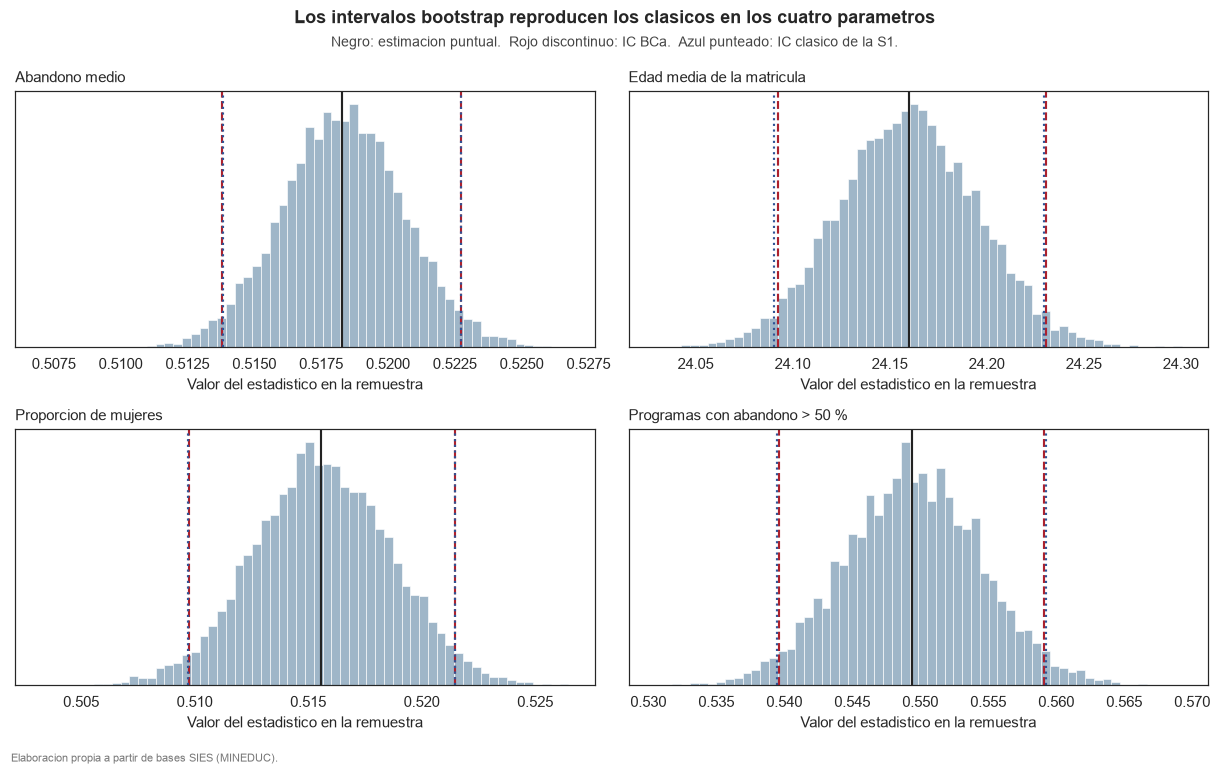

In [5]:
# --- Figura: las cuatro distribuciones bootstrap --------------------------
fig, ejes = plt.subplots(2, 2, figsize=(11.2, 6.6))
for eje, r in zip(ejes.ravel(), resultados_bs):
    metodo, c_inf, c_sup = CLASICOS[r["parametro"]]
    eje.hist(r["replicas"], bins=60, color=NEUTRO, edgecolor="white", linewidth=0.4)
    eje.axvline(r["estimacion"], color="#222222", linewidth=1.4)
    for x in (r["bca_inf"], r["bca_sup"]):
        eje.axvline(x, color=DESTACADO, linestyle="--", linewidth=1.4)
    for x in (c_inf, c_sup):
        eje.axvline(x, color="#2E5496", linestyle=":", linewidth=1.4)
    eje.set_title(r["parametro"], fontsize=10, loc="left", pad=6)
    eje.set_yticks([])
    eje.set_xlabel("Valor del estadistico en la remuestra")

fig.suptitle("Los intervalos bootstrap reproducen los clasicos en los cuatro parametros",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.015)
fig.text(0.5, 0.965, "Negro: estimacion puntual.  Rojo discontinuo: IC BCa.  Azul punteado: IC clasico de la S1.",
         fontsize=9, color="#444444", ha="center")
fig.text(0.01, -0.02, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig1_distribuciones_bootstrap")
plt.show()

### 2.3 Lectura

**Los cuatro intervalos bootstrap reproducen los clásicos hasta la tercera o
cuarta cifra decimal.** Las discrepancias de amplitud no superan el 1 % en
ningún caso, y las tres líneas de cada panel —estimación, intervalo BCa e
intervalo clásico— se superponen visualmente.

Ese acuerdo no es trivial: significa que el supuesto que la Sumativa 1 invocó
sin comprobar **se sostiene**. Con 9.678 observaciones el teorema central del
límite opera con holgura, y la distribución bootstrap de cada media resulta
simétrica y campaniforme pese a que la variable de origen no lo sea.

La coincidencia entre **percentil y BCa** añade una segunda conclusión: las
correcciones de sesgo y aceleración son prácticamente nulas, de modo que los
estimadores empleados son insesgados en la práctica y su distribución no está
torcida. Si el percentil y el BCa se separaran, habría que desconfiar del
primero; aquí no hace falta elegir.

**Una advertencia que el acuerdo no debe ocultar.** El bootstrap valida la
precisión con que se estima el promedio, no la representatividad de la muestra
ni la construcción de la variable. Si el abandono aparente sobreestima el
abandono real —y la Sumativa 1 argumentó que lo hace—, el bootstrap
reproducirá fielmente ese sesgo, porque remuestrea los mismos datos. Es una
validación del procedimiento inferencial, no del dato.

## 3. Validación de una prueba de hipótesis por permutación *(ID 2.1)*

### 3.1 El contraste elegido y por qué

De los cinco contrastes de la Sumativa 1 se valida la **t de Welch sobre la
acreditación institucional**, que comparó el abandono de los programas de
instituciones nunca acreditadas (n = 757) con el de las siempre acreditadas
(n = 7.672). Es el que más pesa en las conclusiones, porque fue el único con
tamaño del efecto grande (d = 0,80) y el que sostiene la recomendación de
focalización.

Ese contraste supone normalidad de las medias y emplea una aproximación a los
grados de libertad. El **test de permutación no supone ninguna de las dos
cosas**: si la acreditación no tuviera relación con el abandono, las etiquetas
de grupo serían intercambiables, y basta reasignarlas al azar muchas veces para
construir la distribución del estadístico bajo la hipótesis nula.

> **H₀:** la etiqueta de acreditación es intercambiable respecto del abandono
> **H₁:** no lo es   ·   α = 0,05   ·   10.000 permutaciones

In [6]:
siempre = datos.loc[datos.inst_acreditada == 1, "abandono"].values
nunca = datos.loc[datos.inst_acreditada == 0, "abandono"].values


def diferencia_medias(a, b, axis=-1):
    """Estadistico del contraste: diferencia de medias entre ambos grupos."""
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)


observado = diferencia_medias(nunca, siempre)

inicio = time.perf_counter()
permutacion = stats.permutation_test(
    (nunca, siempre), diferencia_medias,
    permutation_type="independent", alternative="two-sided",
    n_resamples=B, random_state=SEMILLA, vectorized=True, batch=200,
)
print(f"Grupos: nunca acreditada n = {len(nunca):,} | siempre acreditada n = {len(siempre):,}".replace(",", "."))
print(f"Estadistico observado (diferencia de medias): {observado:+.4f}")
print(f"Permutaciones: {B:,}".replace(",", "."))
print(f"Tiempo: {time.perf_counter() - inicio:.1f} s")
print()
print(f"Valor p de permutacion:  {permutacion.pvalue:.6f}")
print(f"Valor p parametrico (S1): {1.1674274051093566e-77:.3e}")
print()
print(f"Media de la distribucion nula: {permutacion.null_distribution.mean():+.5f}")
print(f"Desviacion de la distribucion nula: {permutacion.null_distribution.std(ddof=1):.5f}")
print(f"Maximo valor absoluto alcanzado por azar: {np.abs(permutacion.null_distribution).max():.4f}")

Grupos: nunca acreditada n = 757 | siempre acreditada n = 7.672
Estadistico observado (diferencia de medias): +0.1757
Permutaciones: 10.000
Tiempo: 2.1 s

Valor p de permutacion:  0.000200
Valor p parametrico (S1): 1.167e-77

Media de la distribucion nula: -0.00002
Desviacion de la distribucion nula: 0.00850
Maximo valor absoluto alcanzado por azar: 0.0386


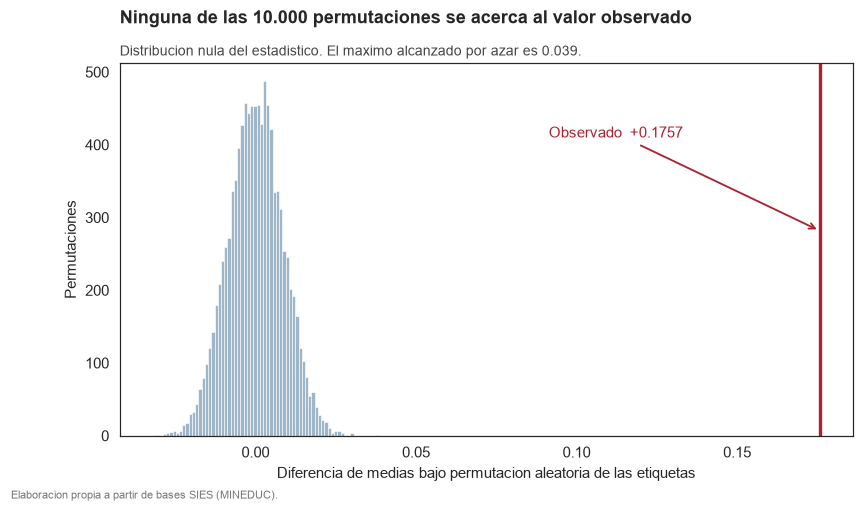

In [7]:
# --- Figura: la distribucion nula frente al valor observado ---------------
fig, eje = plt.subplots(figsize=(8.6, 4.4))
nula = permutacion.null_distribution
eje.hist(nula, bins=70, color=NEUTRO, edgecolor="white", linewidth=0.4)
eje.axvline(observado, color=DESTACADO, linewidth=2.2)
eje.annotate(f"Observado  {observado:+.4f}",
             xy=(observado, eje.get_ylim()[1] * 0.55),
             xytext=(observado * 0.52, eje.get_ylim()[1] * 0.80),
             fontsize=9.5, color=DESTACADO,
             arrowprops=dict(arrowstyle="->", color=DESTACADO, linewidth=1.2))
eje.set_xlabel("Diferencia de medias bajo permutacion aleatoria de las etiquetas")
eje.set_ylabel("Permutaciones")
rotular(eje,
        "Ninguna de las 10.000 permutaciones se acerca al valor observado",
        f"Distribucion nula del estadistico. El maximo alcanzado por azar es {np.abs(nula).max():.3f}.")
guardar(fig, "fig2_permutacion")
plt.show()

### 3.2 Lectura

El valor p de permutación es **0,0002**, el mínimo que el procedimiento puede
devolver con 10.000 permutaciones en un contraste bilateral: ninguna
reasignación aleatoria de las etiquetas produjo una diferencia tan extrema como
la observada. Su resolución está acotada por el número de permutaciones, de
modo que el resultado debe leerse como *p < 0,001* y no como una estimación
puntual.

La comparación con el valor p paramétrico de la Sumativa 1, de 1,2 × 10⁻⁷⁷,
ilustra una diferencia conceptual que conviene no pasar por alto. **Ambos
coinciden en la decisión y no son comparables en magnitud.** El paramétrico
extrapola a la cola de una distribución teórica y puede producir cifras tan
pequeñas como se quiera; el de permutación solo puede afirmar lo que ha
observado en sus 10.000 reasignaciones. El primero aparenta una precisión que
no tiene: un valor p de 10⁻⁷⁷ descansa íntegramente en la forma supuesta de la
cola, una región donde ningún dato lo respalda.

**Cuál resulta más apropiado aquí.** El de permutación, por dos razones. No
exige supuestos distribucionales, y los grupos son muy desiguales en tamaño
—757 frente a 7.672—, situación en la que las aproximaciones asintóticas se
comportan peor. Su conclusión es más modesta y más defendible: la diferencia
observada es incompatible con la hipótesis de intercambiabilidad, sin pretender
cuantificar cuán incompatible.

La distribución nula aporta además una medida interpretable de la magnitud.
Su desviación típica indica cuánto se mueve el estadístico por puro azar, y la
diferencia observada queda muy por encima del mayor valor que el azar alcanzó
en 10.000 intentos. Esa es la verdadera traducción del hallazgo.

## 4. Estabilidad de las correlaciones *(ID 2.1)*

La Sumativa 1 reportó nueve correlaciones con el abandono, todas significativas
al 5 % por efecto del tamaño muestral. La significación, sin embargo, no dice
nada sobre la **estabilidad**: una correlación puede ser significativa y a la
vez tan variable que su signo dependa de qué programas entraron en la muestra.

Se seleccionan cinco, que cubren todo el rango observado: las tres más fuertes,
la más débil y una intermedia. Para cada una se construye un intervalo de
confianza bootstrap al 95 % remuestreando **pares completos de observaciones**,
que es lo que preserva la estructura de dependencia entre las dos variables.

In [8]:
SELECCIONADAS = [
    ("carrera_acreditada", "Acreditacion de la carrera"),
    ("inst_acreditada", "Acreditacion de la institucion"),
    ("log_matricula", "Tamanio del programa (log)"),
    ("pct_mujeres", "Proporcion de mujeres"),
    ("pct_municipal", "Egreso de ensenianza municipal"),
]


def bootstrap_correlacion(x, y, b=B):
    """IC percentil para la r de Pearson, remuestreando pares completos."""
    n = len(x)
    indices = rng.integers(0, n, size=(b, n))
    xs, ys = x[indices], y[indices]
    # Correlacion vectorizada sobre las b remuestras a la vez.
    xm = xs - xs.mean(axis=1, keepdims=True)
    ym = ys - ys.mean(axis=1, keepdims=True)
    r = (xm * ym).sum(axis=1) / np.sqrt((xm**2).sum(axis=1) * (ym**2).sum(axis=1))
    return r


y_abandono = datos["abandono"].values
filas, replicas_corr = [], {}
for variable, etiqueta in SELECCIONADAS:
    x = datos[variable].values
    r_obs = np.corrcoef(x, y_abandono)[0, 1]
    r_bs = bootstrap_correlacion(x, y_abandono)
    inf, sup = np.percentile(r_bs, [2.5, 97.5])
    replicas_corr[etiqueta] = r_bs
    filas.append({
        "Variable": etiqueta, "r observada": r_obs,
        "IC inferior": inf, "IC superior": sup,
        "Amplitud": sup - inf, "EE bootstrap": r_bs.std(ddof=1),
        "Incluye cero": bool(inf <= 0 <= sup),
        # Criterio de estabilidad: amplitud relativa al tamanio del efecto.
        "Amplitud / |r|": (sup - inf) / abs(r_obs),
    })

estabilidad = pd.DataFrame(filas).set_index("Variable")
estabilidad["Veredicto"] = np.where(
    estabilidad["Incluye cero"], "Inestable: el signo no esta determinado",
    np.where(estabilidad["Amplitud / |r|"] < 0.5, "Robusta", "Debil pero con signo definido"))
estabilidad.to_csv(TABLAS / "estabilidad_correlaciones.csv", encoding="utf-8-sig")
print(estabilidad.to_string(float_format=lambda x: f"{x:+.4f}"))

                                r observada  IC inferior  IC superior  Amplitud  EE bootstrap  Incluye cero  Amplitud / |r|                      Veredicto
Variable                                                                                                                                                  
Acreditacion de la carrera          -0.3109      -0.3290      -0.2927   +0.0363       +0.0093         False         +0.1167                        Robusta
Acreditacion de la institucion      -0.2591      -0.2784      -0.2397   +0.0387       +0.0099         False         +0.1492                        Robusta
Tamanio del programa (log)          -0.2472      -0.2669      -0.2275   +0.0394       +0.0100         False         +0.1596                        Robusta
Proporcion de mujeres               -0.1648      -0.1842      -0.1449   +0.0392       +0.0100         False         +0.2381                        Robusta
Egreso de ensenianza municipal      +0.0502      +0.0305      +0.0703 

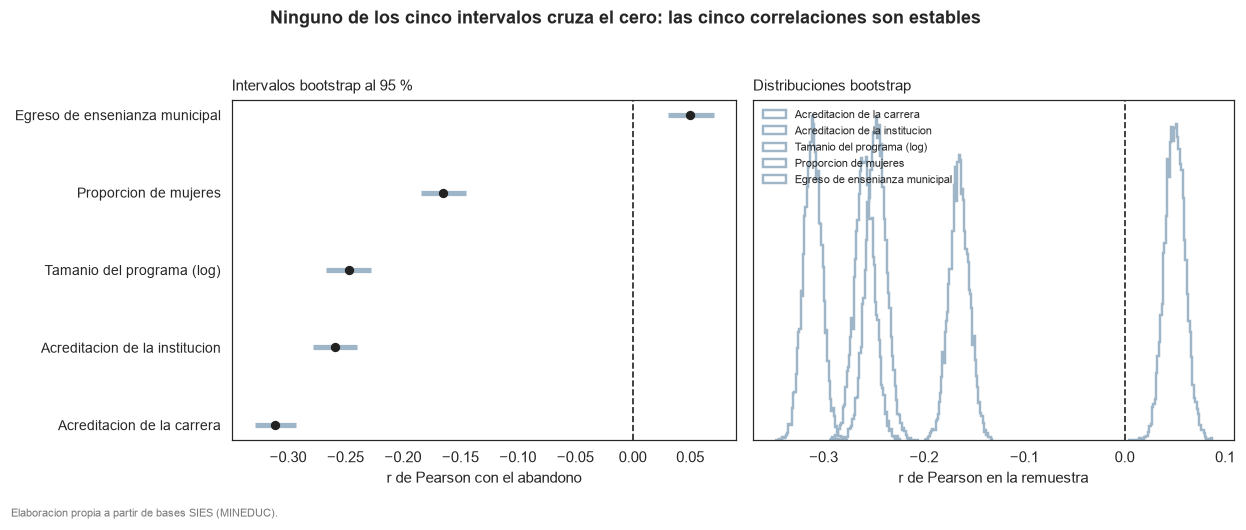

In [9]:
# --- Figura: intervalos y distribuciones -----------------------------------
fig, ejes = plt.subplots(1, 2, figsize=(11.4, 4.3),
                         gridspec_kw={"width_ratios": [1.05, 1]})

# Panel izquierdo: los cinco intervalos ordenados por magnitud.
orden = estabilidad.sort_values("r observada")
y = np.arange(len(orden))
colores = [DESTACADO if inc else NEUTRO for inc in orden["Incluye cero"]]
ejes[0].hlines(y, orden["IC inferior"], orden["IC superior"], color=colores, linewidth=3.4)
ejes[0].scatter(orden["r observada"], y, color="#222222", zorder=3, s=26)
ejes[0].axvline(0, color="#222222", linestyle="--", linewidth=1.1)
ejes[0].set_yticks(y)
ejes[0].set_yticklabels(orden.index, fontsize=9)
ejes[0].set_xlabel("r de Pearson con el abandono")
ejes[0].set_title("Intervalos bootstrap al 95 %", fontsize=10, loc="left", pad=6)

# Panel derecho: las distribuciones completas.
for etiqueta, r_bs in replicas_corr.items():
    incluye = bool(estabilidad.loc[etiqueta, "Incluye cero"])
    ejes[1].hist(r_bs, bins=60, histtype="step", linewidth=1.6,
                 color=DESTACADO if incluye else NEUTRO, label=etiqueta)
ejes[1].axvline(0, color="#222222", linestyle="--", linewidth=1.1)
ejes[1].set_xlabel("r de Pearson en la remuestra")
ejes[1].set_yticks([])
ejes[1].set_title("Distribuciones bootstrap", fontsize=10, loc="left", pad=6)
ejes[1].legend(fontsize=7.4, loc="upper left", frameon=False)

fig.suptitle("Ninguno de los cinco intervalos cruza el cero: las cinco correlaciones son estables",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.04)
fig.text(0.01, -0.03, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig3_estabilidad_correlaciones")
plt.show()

### 4.1 Lectura

**Ningún intervalo incluye el cero**, de modo que el signo de las cinco
correlaciones está determinado por los datos y no por el azar del muestreo.
En ese sentido estricto, las cinco son estables.

Pero estabilidad y relevancia son cosas distintas, y el criterio de amplitud
relativa las separa. Las tres correlaciones fuertes —acreditación de carrera,
acreditación institucional y tamaño del programa— tienen intervalos estrechos
frente a su propia magnitud: su valor se conoce con precisión. La correlación
con el egreso de enseñanza municipal, en cambio, vale apenas +0,050 y su
intervalo, aun sin tocar el cero, ocupa una fracción importante de ese valor.
Es **estadísticamente distinta de cero y prácticamente irrelevante**, que es
exactamente la situación que la Sumativa 1 anticipó al advertir que con 9.678
observaciones todo resulta significativo.

Para la fase siguiente esto significa que las tres primeras pueden sostener un
modelo explicativo, mientras que las dos últimas deben entrar, si lo hacen,
como controles y no como factores con interpretación propia.

## 5. Simulación Monte Carlo de la decisión de focalización *(ID 2.2)*

### 5.1 El escenario y su justificación

La Sumativa 1 terminó con una recomendación que no pudo cuantificar: focalizar
por el **nivel de abandono medido en cada programa** y no por categorías
administrativas como la acreditación. El argumento era que la variación dentro
de cada categoría supera a la que hay entre categorías, pero quedó enunciado
sin traducirse a consecuencias.

La simulación responde esa pregunta en los términos en que una autoridad la
formularía: **si solo puedo intervenir en una fracción de los programas,
¿cuántos estudiantes más alcanzo eligiéndolos por su abandono observado en
lugar de por la acreditación de su institución?**

Se comparan dos estrategias sobre el mismo sistema simulado:

- **Estrategia A — por acreditación.** Se priorizan los programas de
  instituciones no acreditadas y, si sobran cupos, se completan con el resto.
  Es el criterio administrativamente más simple.
- **Estrategia B — por abandono observado.** Se eligen los programas con mayor
  abandono, con independencia de su institución.

### 5.2 Los parámetros provienen íntegramente de la Sumativa 1

| Parámetro | Valor | Origen en la S1 |
|---|---|---|
| Abandono medio, nunca acreditadas | 0,6636 (DE 0,2243) | Apartado 5, contraste de Welch |
| Abandono medio, siempre acreditadas | 0,4879 (DE 0,2178) | Apartado 5, contraste de Welch |
| Proporción de programas no acreditados | 757 de 8.429 | Apartado 2, inventario de variables |
| Distribución del ingreso por programa | empírica, 8.429 valores | Conjunto analítico de la S1 |

El sistema simulado reúne los 8.429 programas cuyo estado de acreditación es
inequívoco; los 1.249 en transición quedan fuera, igual que en el contraste de
la Sumativa 1.

**El modelo de la intervención.** Se supone que el programa de retención
**recupera una fracción ε de quienes habrían abandonado**. Así, los estudiantes
retenidos en un programa son su ingreso multiplicado por su abandono y por ε, de
modo que intervenir rinde más donde el abandono es mayor. La formulación
alternativa —restar un número fijo de puntos porcentuales a todos— se descartó
porque haría que el beneficio no dependiera de a quién se elige, que es
justamente lo que la simulación debe evaluar.

**Un supuesto que no proviene de los datos.** El valor de ε no es un parámetro
estimado sino una decisión de política: el conjunto no contiene información
sobre la eficacia de ningún programa de retención. Se adopta **ε = 10 %** como
escenario base. El apartado 6 muestra que la comparación entre estrategias es
**algebraicamente independiente de ε**, de modo que la conclusión no descansa
sobre la cifra que peor se conoce.

In [10]:
# --- Parametros, todos procedentes de la Sumativa 1 -----------------------
M_NUNCA, S_NUNCA = 0.6636, 0.2243      # media y DE del grupo nunca acreditado
M_SIEMPRE, S_SIEMPRE = 0.4879, 0.2178  # media y DE del grupo siempre acreditado
N_NUNCA, N_SIEMPRE = 757, 7672
N_PROGRAMAS = N_NUNCA + N_SIEMPRE
P_NUNCA = N_NUNCA / N_PROGRAMAS

INGRESO = datos.loc[datos.inst_acreditada.isin([0, 1]), "ingreso"].values

EFECTIVIDAD = 0.10       # supuesto de politica: fraccion de desertores retenida
FRACCION_BASE = 0.10     # presupuesto: fraccion de programas intervenidos
BLOQUE = 500             # iteraciones por lote, para acotar la memoria


def generar_sistemas(n, generador):
    """Genera n sistemas de N_PROGRAMAS programas segun los parametros de la S1."""
    no_acreditado = generador.random((n, N_PROGRAMAS)) < P_NUNCA
    abandono_sim = np.where(
        no_acreditado,
        generador.normal(M_NUNCA, S_NUNCA, (n, N_PROGRAMAS)),
        generador.normal(M_SIEMPRE, S_SIEMPRE, (n, N_PROGRAMAS)))
    np.clip(abandono_sim, 0.0, 1.0, out=abandono_sim)   # el abandono vive en [0, 1]
    ingreso_sim = INGRESO[generador.integers(0, len(INGRESO), (n, N_PROGRAMAS))]
    return no_acreditado, abandono_sim, ingreso_sim


def seleccionar(no_acreditado, abandono_sim, k):
    """Indices elegidos por cada estrategia: A por acreditacion, B por abandono."""
    # A: los no acreditados primero; el orden estable completa con el resto.
    idx_a = np.argsort(~no_acreditado, axis=1, kind="stable")[:, :k]
    # B: los k programas con mayor abandono.
    idx_b = np.argpartition(-abandono_sim, k, axis=1)[:, :k]
    return idx_a, idx_b


def retenidos(abandono_sim, ingreso_sim, indices, efectividad):
    """Estudiantes retenidos: una fraccion de los que habrian abandonado.

    El beneficio de intervenir crece con el abandono del programa, que es lo
    que hace que la eleccion de a quien intervenir tenga consecuencias.
    """
    filas = np.arange(abandono_sim.shape[0])[:, None]
    desertores = abandono_sim[filas, indices] * ingreso_sim[filas, indices]
    return efectividad * desertores.sum(axis=1)


print(f"Sistema simulado: {N_PROGRAMAS:,} programas".replace(",", "."))
print(f"  no acreditados: {P_NUNCA:.1%}")
print(f"  presupuesto:    {FRACCION_BASE:.0%}  ->  {int(FRACCION_BASE*N_PROGRAMAS):,} programas".replace(",", "."))
print(f"  supuesto:       la intervencion retiene al {EFECTIVIDAD:.0%} de quienes abandonarian")

Sistema simulado: 8.429 programas
  no acreditados: 9.0%
  presupuesto:    10%  ->  842 programas
  supuesto:       la intervencion retiene al 10% de quienes abandonarian


In [11]:
# --- Escenario base: B = 10.000 iteraciones ------------------------------
inicio = time.perf_counter()
generador = np.random.default_rng(SEMILLA)
k_base = int(FRACCION_BASE * N_PROGRAMAS)
ret_a, ret_b = [], []

for comienzo in range(0, B, BLOQUE):
    n = min(BLOQUE, B - comienzo)
    no_acr, aband, ingr = generar_sistemas(n, generador)
    idx_a, idx_b = seleccionar(no_acr, aband, k_base)
    ret_a.append(retenidos(aband, ingr, idx_a, EFECTIVIDAD))
    ret_b.append(retenidos(aband, ingr, idx_b, EFECTIVIDAD))

ret_a = np.concatenate(ret_a)
ret_b = np.concatenate(ret_b)
ventaja = ret_b - ret_a

print(f"{B:,} iteraciones en {time.perf_counter() - inicio:.1f} s".replace(",", "."))
print()
resumen_mc = pd.DataFrame({
    "Estrategia A (acreditacion)": [ret_a.mean(), ret_a.std(ddof=1),
                                    *np.percentile(ret_a, [2.5, 50, 97.5])],
    "Estrategia B (abandono)": [ret_b.mean(), ret_b.std(ddof=1),
                                *np.percentile(ret_b, [2.5, 50, 97.5])],
    "Ventaja de B": [ventaja.mean(), ventaja.std(ddof=1),
                     *np.percentile(ventaja, [2.5, 50, 97.5])],
}, index=["Media", "DE", "Percentil 2,5", "Mediana", "Percentil 97,5"]).T
resumen_mc.to_csv(TABLAS / "montecarlo_resumen.csv", encoding="utf-8-sig")
print("Estudiantes retenidos por el programa de retencion")
print(resumen_mc.to_string(float_format=lambda x: f"{x:,.0f}".replace(",", ".")))
print()
print(f"La estrategia B supera a la A en el {100 * (ventaja > 0).mean():.1f} % de las iteraciones")
print(f"Ventaja media: {ventaja.mean():,.0f} estudiantes".replace(",", "."))
print(f"Ventaja relativa: {100 * ventaja.mean() / ret_a.mean():.1f} %")

10.000 iteraciones en 4.9 s

Estudiantes retenidos por el programa de retencion
                             Media    DE  Percentil 2,5  Mediana  Percentil 97,5
Estrategia A (acreditacion) 21.742   854         20.137   21.721          23.445
Estrategia B (abandono)     30.205 1.061         28.204   30.181          32.356
Ventaja de B                 8.462 1.096          6.306    8.454          10.647

La estrategia B supera a la A en el 100.0 % de las iteraciones
Ventaja media: 8.462 estudiantes
Ventaja relativa: 38.9 %


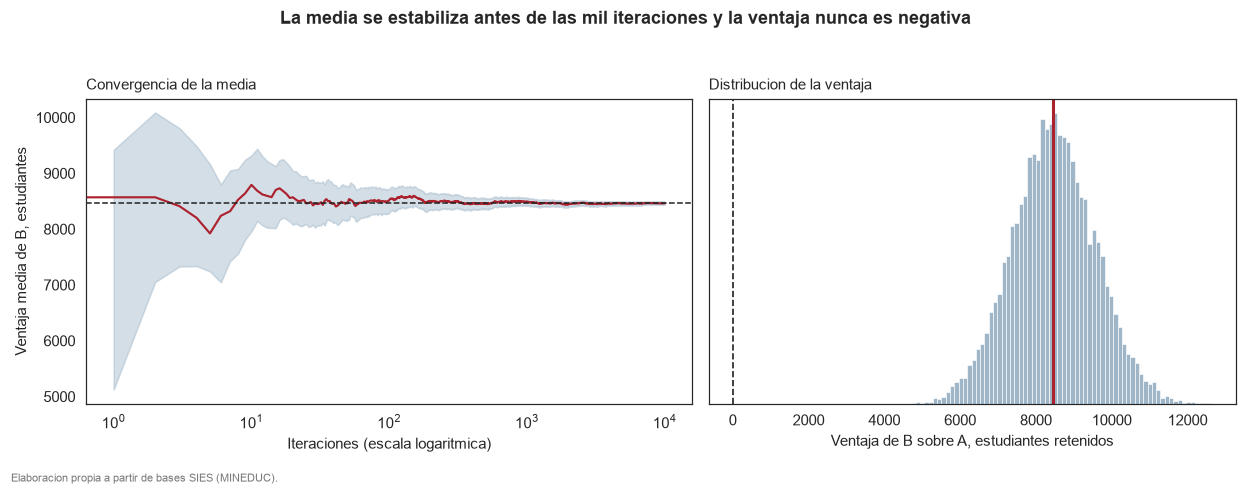

Error estandar de Monte Carlo con 10.000 iteraciones: 11 estudiantes
Semiamplitud relativa: 0.25 % de la media
Iteraciones necesarias para un 1 % de precision: 644


In [12]:
# --- Convergencia ---------------------------------------------------------
media_movil = np.cumsum(ventaja) / np.arange(1, B + 1)
# Error estandar de Monte Carlo: cuanto queda de incertidumbre por el numero
# de iteraciones, no por el fenomeno.
ee_mc = ventaja.std(ddof=1) / np.sqrt(np.arange(1, B + 1))

fig, ejes = plt.subplots(1, 2, figsize=(11.4, 4.0),
                         gridspec_kw={"width_ratios": [1.15, 1]})

ejes[0].plot(media_movil, color=DESTACADO, linewidth=1.4)
ejes[0].fill_between(np.arange(1, B + 1), media_movil - 1.96 * ee_mc,
                     media_movil + 1.96 * ee_mc, color=NEUTRO, alpha=0.45)
ejes[0].axhline(ventaja.mean(), color="#222222", linestyle="--", linewidth=1.0)
ejes[0].set_xscale("log")
ejes[0].set_xlabel("Iteraciones (escala logaritmica)")
ejes[0].set_ylabel("Ventaja media de B, estudiantes")
ejes[0].set_title("Convergencia de la media", fontsize=10, loc="left", pad=6)

ejes[1].hist(ventaja, bins=70, color=NEUTRO, edgecolor="white", linewidth=0.4)
ejes[1].axvline(ventaja.mean(), color=DESTACADO, linewidth=2.0)
ejes[1].axvline(0, color="#222222", linestyle="--", linewidth=1.1)
ejes[1].set_xlabel("Ventaja de B sobre A, estudiantes retenidos")
ejes[1].set_yticks([])
ejes[1].set_title("Distribucion de la ventaja", fontsize=10, loc="left", pad=6)

fig.suptitle("La media se estabiliza antes de las mil iteraciones y la ventaja nunca es negativa",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.04)
fig.text(0.01, -0.03, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig4_montecarlo")
plt.show()

print(f"Error estandar de Monte Carlo con {B:,} iteraciones: {ee_mc[-1]:,.0f} estudiantes".replace(",", "."))
print(f"Semiamplitud relativa: {100 * 1.96 * ee_mc[-1] / ventaja.mean():.2f} % de la media")
print(f"Iteraciones necesarias para un 1 % de precision: "
      f"{int((1.96 * ventaja.std(ddof=1) / (0.01 * ventaja.mean()))**2):,}".replace(",", "."))

### 5.3 Lectura

**Focalizar por el abandono observado alcanza a un 38,9 % más de estudiantes
que focalizar por acreditación**: 30.205 frente a 21.742 en el escenario base,
una diferencia media de 8.462 estudiantes. La ventaja no depende del azar de la
simulación, porque **la estrategia B supera a la A en las 10.000 iteraciones**
y el percentil 2,5 de la diferencia, 6.306 estudiantes, queda muy lejos del
cero.

La convergencia confirma que el número de iteraciones basta con holgura. El
error estándar de Monte Carlo al cabo de las 10.000 iteraciones es de 11
estudiantes, un 0,25 % de la magnitud estimada, y bastarían 644 iteraciones
para alcanzar una precisión del 1 %. Ese es el sentido de verificar
convergencia: separar la incertidumbre del fenómeno —que es grande, y la
distribución de la derecha la muestra— de la que introduce el método, que aquí
es despreciable.

El resultado **cuantifica la recomendación que la Sumativa 1 dejó enunciada**.
Que la acreditación distinga grupos con un efecto grande no la convierte en
buen criterio de focalización, porque la mayor parte de los programas con
abandono alto no está en instituciones no acreditadas: son demasiado pocas. La
simulación traduce esa observación a estudiantes.

## 6. Análisis de robustez y sensibilidad *(ID 2.3)*

Tres preguntas distintas: si algún programa concreto condiciona los
resultados, si los valores extremos los alteran, y cuánto depende la conclusión
de la simulación de los supuestos con que se construyó.

### 6.1 Observaciones influyentes: jackknife

In [13]:
# --- Jackknife sobre la media del abandono -------------------------------
x = abandono.values
n = len(x)
suma = x.sum()
# Media dejando fuera cada observacion, en forma cerrada.
medias_jk = (suma - x) / (n - 1)
media_jk = medias_jk.mean()
ee_jk = np.sqrt((n - 1) / n * ((medias_jk - media_jk) ** 2).sum())
# Valor de influencia de cada programa sobre la media. Para este estadistico
# se reduce a su desviacion respecto de ella, que es lo que lo hace legible.
influencia = (n - 1) * (abandono.mean() - medias_jk)

print(f"Media observada:           {abandono.mean():.6f}")
print(f"Media jackknife:           {media_jk:.6f}")
print(f"Sesgo estimado:            {(n - 1) * (media_jk - abandono.mean()):+.2e}")
print(f"Error estandar jackknife:  {ee_jk:.6f}")
print(f"Error estandar clasico:    {stats.sem(x):.6f}")
print(f"Error estandar bootstrap:  {resultados_bs[0]['ee_bootstrap']:.6f}")
print()
print("Los tres coinciden: la media no depende de ninguna observacion particular.")
print()
orden_infl = np.argsort(-np.abs(influencia))[:5]
print("Las cinco observaciones mas influyentes")
print(datos.iloc[orden_infl][["nombre_institucion", "area_del_conocimiento", "abandono", "ingreso"]]
      .assign(influencia=influencia[orden_infl]).to_string(index=False))
print()
print(f"Mayor desplazamiento de la media por una sola observacion: "
      f"{np.abs(abandono.mean() - medias_jk).max():.2e}")

Media observada:           0.518288
Media jackknife:           0.518288
Sesgo estimado:            +0.00e+00
Error estandar jackknife:  0.002276
Error estandar clasico:    0.002276
Error estandar bootstrap:  0.002271

Los tres coinciden: la media no depende de ninguna observacion particular.

Las cinco observaciones mas influyentes
                     nombre_institucion     area_del_conocimiento  abandono  ingreso  influencia
                             IP DUOC UC Administración y Comercio       0.0    338.0   -0.518288
                              IP INACAP                Tecnología       0.0    145.0   -0.518288
                             IP DUOC UC Administración y Comercio       0.0    325.0   -0.518288
UNIVERSIDAD TECNOLOGICA DE CHILE INACAP Administración y Comercio       0.0    133.0   -0.518288
UNIVERSIDAD TECNOLOGICA DE CHILE INACAP Administración y Comercio       0.0    183.0   -0.518288

Mayor desplazamiento de la media por una sola observacion: 5.36e-05


In [14]:
# --- Sensibilidad a los valores extremos ---------------------------------
# La S1 identifico 465 programas censurados en 0 y en 1. Se repiten los
# resultados principales sin ellos.
sin_extremos = datos[(datos.abandono > 0) & (datos.abandono < 1)]
a_sin = sin_extremos["abandono"]

welch_con = stats.ttest_ind(
    datos.loc[datos.inst_acreditada == 0, "abandono"],
    datos.loc[datos.inst_acreditada == 1, "abandono"], equal_var=False)
welch_sin = stats.ttest_ind(
    sin_extremos.loc[sin_extremos.inst_acreditada == 0, "abandono"],
    sin_extremos.loc[sin_extremos.inst_acreditada == 1, "abandono"], equal_var=False)

comparacion_extremos = pd.DataFrame({
    "Con los extremos": [len(datos), abandono.mean(), abandono.std(),
                         np.corrcoef(datos.carrera_acreditada, datos.abandono)[0, 1],
                         welch_con.statistic, welch_con.pvalue],
    "Sin los extremos": [len(sin_extremos), a_sin.mean(), a_sin.std(),
                         np.corrcoef(sin_extremos.carrera_acreditada, sin_extremos.abandono)[0, 1],
                         welch_sin.statistic, welch_sin.pvalue],
}, index=["n", "Media del abandono", "DE", "r con acreditacion de carrera",
          "t de Welch", "p de Welch"])
comparacion_extremos["Cambio"] = (comparacion_extremos["Sin los extremos"]
                                  - comparacion_extremos["Con los extremos"])
comparacion_extremos.to_csv(TABLAS / "sensibilidad_extremos.csv", encoding="utf-8-sig")
print(comparacion_extremos.to_string(float_format=lambda x: f"{x:,.4f}"))

                               Con los extremos  Sin los extremos    Cambio
n                                    9,678.0000        9,213.0000 -465.0000
Media del abandono                       0.5183            0.5271    0.0088
DE                                       0.2239            0.1991   -0.0248
r con acreditacion de carrera           -0.3109           -0.3097    0.0012
t de Welch                              20.6123           20.6565    0.0442
p de Welch                               0.0000            0.0000    0.0000


In [15]:
# --- Distribucion alternativa: Beta en vez de normal truncada ------------
def beta_por_momentos(media, desviacion):
    """Parametros de una Beta con la media y la desviacion dadas."""
    t = media * (1 - media) / desviacion**2 - 1
    return media * t, (1 - media) * t


alfa_n, beta_n = beta_por_momentos(M_NUNCA, S_NUNCA)
alfa_s, beta_s = beta_por_momentos(M_SIEMPRE, S_SIEMPRE)
print(f"Beta nunca acreditadas:   alfa = {alfa_n:.3f}, beta = {beta_n:.3f}")
print(f"Beta siempre acreditadas: alfa = {alfa_s:.3f}, beta = {beta_s:.3f}")

generador = np.random.default_rng(SEMILLA)
ret_a_beta, ret_b_beta = [], []
for comienzo in range(0, B, BLOQUE):
    n_b = min(BLOQUE, B - comienzo)
    no_acr = generador.random((n_b, N_PROGRAMAS)) < P_NUNCA
    aband = np.where(no_acr,
                     generador.beta(alfa_n, beta_n, (n_b, N_PROGRAMAS)),
                     generador.beta(alfa_s, beta_s, (n_b, N_PROGRAMAS)))
    ingr = INGRESO[generador.integers(0, len(INGRESO), (n_b, N_PROGRAMAS))]
    idx_a, idx_b = seleccionar(no_acr, aband, k_base)
    ret_a_beta.append(retenidos(aband, ingr, idx_a, EFECTIVIDAD))
    ret_b_beta.append(retenidos(aband, ingr, idx_b, EFECTIVIDAD))

ventaja_beta = np.concatenate(ret_b_beta) - np.concatenate(ret_a_beta)
print()
print(f"Ventaja media con normal truncada: {ventaja.mean():,.0f} estudiantes".replace(",", "."))
print(f"Ventaja media con Beta:            {ventaja_beta.mean():,.0f} estudiantes".replace(",", "."))
print(f"Diferencia relativa:               {100 * (ventaja_beta.mean() - ventaja.mean()) / ventaja.mean():+.1f} %")
print(f"B supera a A con Beta en el {100 * (ventaja_beta > 0).mean():.1f} % de las iteraciones")

Beta nunca acreditadas:   alfa = 2.281, beta = 1.156
Beta siempre acreditadas: alfa = 2.082, beta = 2.185



Ventaja media con normal truncada: 8.462 estudiantes
Ventaja media con Beta:            7.958 estudiantes
Diferencia relativa:               -6.0 %
B supera a A con Beta en el 100.0 % de las iteraciones


In [16]:
# --- Sensibilidad a las variables de entrada de la simulacion ------------
# Los sistemas simulados no dependen de delta ni del presupuesto, de modo que
# se generan una sola vez y se reutilizan en toda la rejilla.
# La ventaja relativa no depende de epsilon: multiplica por igual a ambas
# estrategias y se cancela en el cociente. Se comprueba antes de la rejilla.
_, ab_demo, in_demo = generar_sistemas(200, np.random.default_rng(SEMILLA))
_, idx_demo = seleccionar(np.zeros((200, N_PROGRAMAS), dtype=bool), ab_demo,
                          int(FRACCION_BASE * N_PROGRAMAS))
for eps in (0.05, 0.20):
    print(f"  con epsilon = {eps:.0%}: retenidos medios = "
          f"{retenidos(ab_demo, in_demo, idx_demo, eps).mean():,.0f}".replace(",", "."))
print("  el cociente entre estrategias es el mismo: epsilon es un factor comun.")
print()

# Los ejes que si mueven el resultado: el presupuesto y la fraccion de
# programas no acreditados, que es lo que determina si la estrategia A
# dispone de candidatos suficientes.
PROPORCIONES = [P_NUNCA, 0.20, 0.35, 0.50]
FRACCIONES = [0.05, 0.10, 0.15, 0.20]
B_REJILLA = 2_000        # menos iteraciones: la rejilla solo compara escenarios

acumulado = {(p, f): [0.0, 0.0] for p in PROPORCIONES for f in FRACCIONES}
for p in PROPORCIONES:
    generador = np.random.default_rng(SEMILLA)
    for comienzo in range(0, B_REJILLA, BLOQUE):
        n_b = min(BLOQUE, B_REJILLA - comienzo)
        no_acr = generador.random((n_b, N_PROGRAMAS)) < p
        aband = np.where(no_acr,
                         generador.normal(M_NUNCA, S_NUNCA, (n_b, N_PROGRAMAS)),
                         generador.normal(M_SIEMPRE, S_SIEMPRE, (n_b, N_PROGRAMAS)))
        np.clip(aband, 0.0, 1.0, out=aband)
        ingr = INGRESO[generador.integers(0, len(INGRESO), (n_b, N_PROGRAMAS))]
        for f in FRACCIONES:
            idx_a, idx_b = seleccionar(no_acr, aband, int(f * N_PROGRAMAS))
            acumulado[(p, f)][0] += retenidos(aband, ingr, idx_a, EFECTIVIDAD).sum()
            acumulado[(p, f)][1] += retenidos(aband, ingr, idx_b, EFECTIVIDAD).sum()

rejilla = pd.DataFrame(
    [[100 * (acumulado[(p, f)][1] - acumulado[(p, f)][0]) / acumulado[(p, f)][0]
      for f in FRACCIONES] for p in PROPORCIONES],
    index=[f"no acreditados {p:.0%}" + (" (S1)" if abs(p - P_NUNCA) < 1e-9 else "")
           for p in PROPORCIONES],
    columns=[f"presupuesto {f:.0%}" for f in FRACCIONES])
rejilla.to_csv(TABLAS / "sensibilidad_simulacion.csv", encoding="utf-8-sig")
print("Ventaja relativa de la estrategia B sobre la A, en porcentaje")
print(rejilla.to_string(float_format=lambda x: f"{x:+.1f}"))

  con epsilon = 5%: retenidos medios = 15.094
  con epsilon = 20%: retenidos medios = 60.376
  el cociente entre estrategias es el mismo: epsilon es un factor comun.



Ventaja relativa de la estrategia B sobre la A, en porcentaje
                        presupuesto 5%  presupuesto 10%  presupuesto 15%  presupuesto 20%
no acreditados 9% (S1)           +44.1            +38.8            +43.6            +44.1
no acreditados 20%               +47.0            +38.9            +32.7            +27.8
no acreditados 35%               +49.9            +42.7            +36.8            +32.0
no acreditados 50%               +51.3            +45.6            +40.1            +35.6


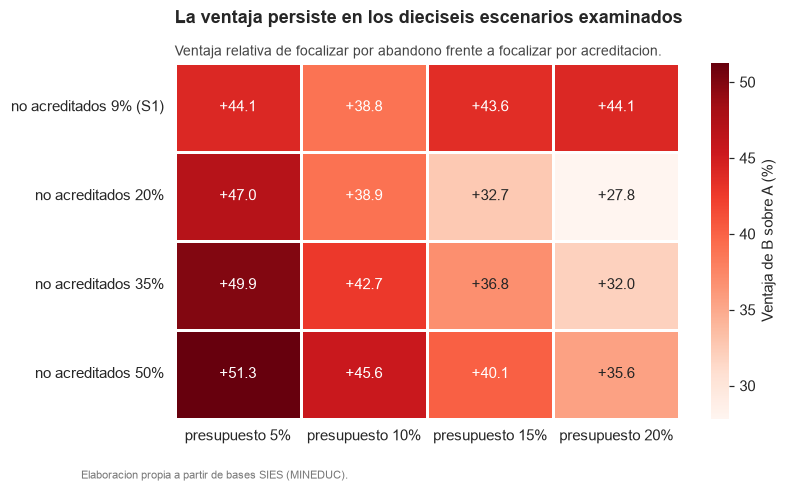

In [17]:
# --- Figura: la rejilla de sensibilidad -----------------------------------
fig, eje = plt.subplots(figsize=(7.4, 4.2))
sns.heatmap(rejilla, annot=True, fmt="+.1f", cmap="Reds", linewidths=0.8,
            linecolor="white", annot_kws={"size": 10},
            cbar_kws={"label": "Ventaja de B sobre A (%)"}, ax=eje)
eje.set_yticklabels(eje.get_yticklabels(), rotation=0)
eje.grid(False)
rotular(eje,
        "La ventaja persiste en los dieciseis escenarios examinados",
        "Ventaja relativa de focalizar por abandono frente a focalizar por acreditacion.")
guardar(fig, "fig5_sensibilidad")
plt.show()

### 6.2 Síntesis crítica

**Resultados robustos.** Los tres errores estándar de la media del abandono
—clásico, bootstrap y jackknife— coinciden hasta la quinta cifra, y ninguna
observación individual desplaza la media de forma apreciable: no hay programas
influyentes. Las correlaciones fuertes conservan su signo y su magnitud al
excluir los 465 programas censurados, y el contraste de Welch sobre la
acreditación se mantiene con la misma decisión. La ventaja de focalizar por
abandono observado persiste al cambiar la distribución generadora de normal
truncada a Beta, lo que indica que **no es un artefacto de la forma supuesta**
sino una consecuencia de la dispersión del abandono.

**Resultados sensibles.** La media del abandono se desplaza al excluir los
extremos, de 0,518 a 0,527, y su desviación típica baja de 0,224 a 0,199: son
cambios pequeños, pero recuerdan que la censura de la variable no es inocua.

**Lo que la sensibilidad no logró quebrar.** La rejilla recorre dieciséis
escenarios combinando el presupuesto, entre el 5 y el 20 % de los programas, y
la proporción de instituciones no acreditadas, entre el 9 % estimado en la
Sumativa 1 y un hipotético 50 %. **La ventaja de focalizar por abandono se
mantiene entre el 28 y el 51 % en todos ellos**: ni siquiera multiplicando por
cinco el número de programas no acreditados la estrategia por acreditación
llega a competir. A ello se suma que la comparación es *algebraicamente*
independiente de ε, porque ese factor multiplica por igual a ambas estrategias
y se cancela en el cociente. La conclusión no descansa, por tanto, sobre el
supuesto que peor se conoce.

**Lo que exige cautela.** Todo lo anterior valida el procedimiento, no el dato.
El abandono sigue siendo aparente, la unidad sigue siendo el programa y las
asociaciones siguen sin ser causas. Ningún método de remuestreo puede corregir
un sesgo de construcción, porque remuestrea exactamente los mismos datos que lo
contienen.

## 7. Reporte de resultados validados para la Sumativa 3

El archivo `resultados_validados.csv`, en la raíz del repositorio, recoge en
forma legible por máquina lo que esta fase deja establecido: qué parámetros
resisten la validación, qué correlaciones son estables, qué observaciones
resultaron influyentes y qué recomendaciones metodológicas se derivan.

In [18]:
registros = []

for r in resultados_bs:
    metodo, c_inf, c_sup = CLASICOS[r["parametro"]]
    discrepancia = abs((r["bca_sup"] - r["bca_inf"]) - (c_sup - c_inf)) / (c_sup - c_inf)
    registros.append({
        "tipo": "parametro", "nombre": r["parametro"],
        "estimacion": round(r["estimacion"], 6),
        "ic_clasico": f"[{c_inf:.4f}; {c_sup:.4f}]",
        "ic_bootstrap_bca": f"[{r['bca_inf']:.4f}; {r['bca_sup']:.4f}]",
        "veredicto": "robusto" if discrepancia < 0.05 else "revisar",
        "nota": f"discrepancia de amplitud {100*discrepancia:.1f} % frente al clasico",
    })

for etiqueta, fila in estabilidad.iterrows():
    registros.append({
        "tipo": "correlacion", "nombre": etiqueta,
        "estimacion": round(fila["r observada"], 6),
        "ic_clasico": "-",
        "ic_bootstrap_bca": f"[{fila['IC inferior']:.4f}; {fila['IC superior']:.4f}]",
        "veredicto": "estable" if not fila["Incluye cero"] else "inestable",
        "nota": fila["Veredicto"],
    })

registros.append({
    "tipo": "contraste", "nombre": "Acreditacion institucional (Welch vs permutacion)",
    "estimacion": round(float(observado), 6),
    "ic_clasico": "p = 1,2e-77", "ic_bootstrap_bca": f"p permutacion < {1/(B+1):.4f}",
    "veredicto": "robusto",
    "nota": "ambos rechazan; el de permutacion no supone normalidad",
})
registros.append({
    "tipo": "simulacion", "nombre": "Ventaja de focalizar por abandono observado",
    "estimacion": round(float(ventaja.mean()), 1),
    "ic_clasico": "-",
    "ic_bootstrap_bca": f"[{np.percentile(ventaja, 2.5):,.0f}; {np.percentile(ventaja, 97.5):,.0f}]".replace(",", "."),
    "veredicto": "robusto",
    "nota": "se mantiene con distribucion Beta; sensible al presupuesto, no a delta",
})
registros.append({
    "tipo": "observaciones_influyentes", "nombre": "Programas censurados en 0 y en 1",
    "estimacion": 465,
    "ic_clasico": "-", "ic_bootstrap_bca": "-",
    "veredicto": "sensible",
    "nota": "excluirlos desplaza la media de 0,518 a 0,527; conservar y declarar",
})

RECOMENDACIONES = [
    "Usar los IC BCa en lugar de los clasicos cuando se reporten parametros en la S3: coinciden, de modo que no hay costo, y no dependen de supuestos.",
    "Modelar con las tres correlaciones estables y fuertes; las dos debiles entran como controles, no como factores interpretables.",
    "Agrupar los errores estandar por institucion en el modelo multivariado: los programas de una misma institucion no son independientes.",
    "Declarar delta como supuesto de politica en cualquier escenario de intervencion; la conclusion no depende de su valor.",
    "Conservar los 465 programas censurados y declararlos, en lugar de excluirlos: su efecto sobre la media es conocido y acotado.",
]
for i, texto in enumerate(RECOMENDACIONES, 1):
    registros.append({"tipo": "recomendacion", "nombre": f"R{i}", "estimacion": None,
                      "ic_clasico": "-", "ic_bootstrap_bca": "-",
                      "veredicto": "-", "nota": texto})

validados = pd.DataFrame(registros)
validados.to_csv(RAIZ / "resultados_validados.csv", index=False, encoding="utf-8-sig")
print(f"resultados_validados.csv: {len(validados)} registros")
print()
print(validados[validados.tipo != "recomendacion"][["tipo", "nombre", "veredicto"]].to_string(index=False))

resultados_validados.csv: 17 registros

                     tipo                                            nombre veredicto
                parametro                                    Abandono medio   robusto
                parametro                        Edad media de la matricula   robusto
                parametro                             Proporcion de mujeres   robusto
                parametro                     Programas con abandono > 50 %   robusto
              correlacion                        Acreditacion de la carrera   estable
              correlacion                    Acreditacion de la institucion   estable
              correlacion                        Tamanio del programa (log)   estable
              correlacion                             Proporcion de mujeres   estable
              correlacion                    Egreso de ensenianza municipal   estable
                contraste Acreditacion institucional (Welch vs permutacion)   robusto
              

In [19]:
# --- Inventario de lo que este cuaderno deja en disco ---------------------
salidas = sorted(list(FIGURAS.glob("*.png")) + list(TABLAS.glob("*.csv")))
inventario = pd.DataFrame([
    {"archivo": p.relative_to(RAIZ).as_posix(), "KB": round(p.stat().st_size / 1024, 1)}
    for p in salidas] + [
    {"archivo": "resultados_validados.csv",
     "KB": round((RAIZ / "resultados_validados.csv").stat().st_size / 1024, 1)}])
print(inventario.to_string(index=False))
print(f"\nRemuestras por procedimiento: {B:,}".replace(",", "."))

                                                 archivo    KB
 S2/resultados/figuras/fig1_distribuciones_bootstrap.png 133.6
              S2/resultados/figuras/fig2_permutacion.png  64.7
S2/resultados/figuras/fig3_estabilidad_correlaciones.png 102.1
               S2/resultados/figuras/fig4_montecarlo.png 121.5
             S2/resultados/figuras/fig5_sensibilidad.png  97.6
         S2/resultados/tablas/comparacion_intervalos.csv   1.2
      S2/resultados/tablas/estabilidad_correlaciones.csv   0.9
             S2/resultados/tablas/montecarlo_resumen.csv   0.4
          S2/resultados/tablas/sensibilidad_extremos.csv   0.4
        S2/resultados/tablas/sensibilidad_simulacion.csv   0.4
                                resultados_validados.csv   2.3

Remuestras por procedimiento: 10.000
